# PPE Detection

This notebook uses the five existing trained models: YOLOv8n, YOLOv10n,
YOLO11n, YOLOv8s, and YOLO11s. Training is disabled by default so the
saved `best.pt` files are not changed.


## Import Libraries


In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from PIL import Image
from IPython.display import display

PROJECT_DIR = Path.cwd()
RUN_TRAINING = True
IMAGE_SIZE = 640

model_paths = {
    "YOLOv8n": PROJECT_DIR / "models" / "yolo8n_best.pt",
    "YOLOv10n": PROJECT_DIR / "models" / "yolo10n_best.pt",
    "YOLO11n": PROJECT_DIR / "models" / "yolo11n_best.pt",
    "YOLOv8s": PROJECT_DIR / "models" / "yolo8s_best.pt",
    "YOLO11s": PROJECT_DIR / "models" / "yolo11s_best.pt",
}
print("Training enabled:", RUN_TRAINING)
print(PROJECT_DIR)


Training enabled: True
d:\CaseStudyGroup4\PPE_Detection_Project


## Dataset


In [2]:
from pathlib import Path
import yaml

PROJECT_DIR = Path(r"D:\CaseStudyGroup4\PPE_Detection_Project")
data_yaml = PROJECT_DIR / "data" / "data.yaml"

with open(data_yaml, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

# Read class names in class-ID order.
names = data_config["names"]
class_names = (
    [names[key] for key in sorted(names, key=int)]
    if isinstance(names, dict)
    else list(names)
)

dataset_dir = Path(data_config["path"])
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

print("Classes:", len(class_names))
print(class_names)

for split_name, split_key in [
    ("Train", "train"),
    ("Validation", "val"),
    ("Test", "test"),
]:
    image_folder = dataset_dir / data_config[split_key]

    print(f"\n{split_name} folder: {image_folder}")
    print("Folder exists:", image_folder.is_dir())

    if not image_folder.is_dir():
        print("Folder missing — check your actual dataset structure.")
        continue

    image_count = sum(
        1
        for file in image_folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    )

    print(f"{split_name}: {image_count} images")

Classes: 11
['helmet', 'gloves', 'vest', 'boots', 'goggles', 'none', 'Person', 'no_helmet', 'no_goggle', 'no_gloves', 'no_boots']

Train folder: D:\CaseStudyGroup4\PPE_Detection_Project\data\images\train
Folder exists: True
Train: 1132 images

Validation folder: D:\CaseStudyGroup4\PPE_Detection_Project\data\images\val
Folder exists: True
Validation: 143 images

Test folder: D:\CaseStudyGroup4\PPE_Detection_Project\data\images\test
Folder exists: True
Test: 141 images


## Data Cleaning


In [3]:
from pathlib import Path
import pandas as pd

dataset_dir = Path(data_config["path"])
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

cleaning_rows = []

for split_name, split_key in [
    ("Train", "train"),
    ("Validation", "val"),
    ("Test", "test"),
]:
    image_folder = dataset_dir / data_config[split_key]

    # Replace the "images" directory component with "labels".
    parts = list(image_folder.parts)
    if "images" not in parts:
        raise ValueError(f"Cannot derive labels folder from: {image_folder}")

    images_index = len(parts) - 1 - parts[::-1].index("images")
    parts[images_index] = "labels"
    label_folder = Path(*parts)

    if not image_folder.is_dir():
        raise FileNotFoundError(f"Images folder does not exist: {image_folder}")

    if not label_folder.is_dir():
        raise FileNotFoundError(f"Labels folder does not exist: {label_folder}")

    image_files = [
        path
        for path in image_folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]

    missing_labels = 0
    mixed_format_rows = 0

    for image_path in image_files:
        relative_path = image_path.relative_to(image_folder)
        label_path = (label_folder / relative_path).with_suffix(".txt")

        if not label_path.is_file():
            missing_labels += 1
            continue

        for line in label_path.read_text(encoding="utf-8").splitlines():
            # Ignore blank lines.
            if line.strip() and len(line.split()) != 5:
                mixed_format_rows += 1

    cleaning_rows.append([
        split_name,
        len(image_files),
        missing_labels,
        mixed_format_rows,
    ])

cleaning_table = pd.DataFrame(
    cleaning_rows,
    columns=["Split", "Images", "Missing Labels", "Mixed Format Rows"],
)

display(cleaning_table)

,Split,Images,Missing Labels,Mixed Format Rows
0,Train,1132,0,0
1,Validation,143,0,0
2,Test,141,0,0


## Data Visualization


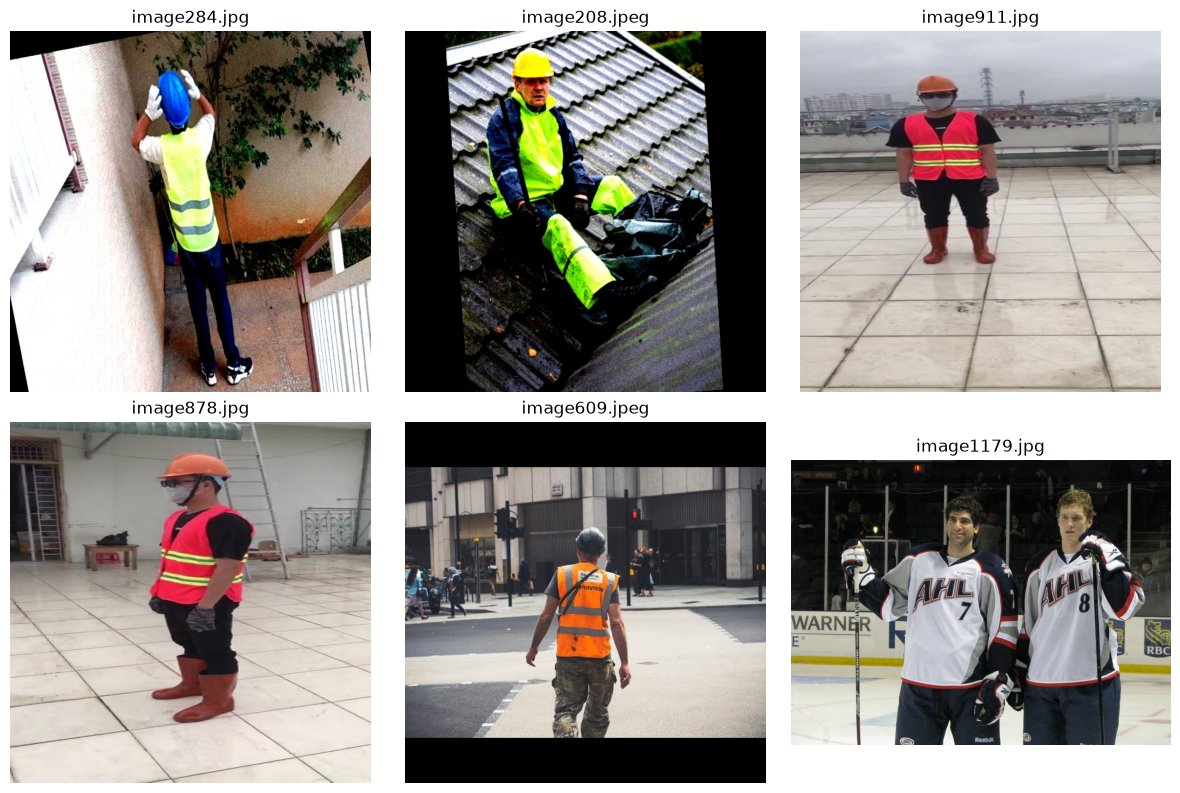

In [4]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

train_image_folder = Path(data_config["path"]) / data_config["train"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

if not train_image_folder.is_dir():
    raise FileNotFoundError(f"Training folder not found: {train_image_folder}")

training_images = [
    path
    for path in train_image_folder.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

if not training_images:
    raise ValueError(f"No images found in: {train_image_folder}")

samples = random.sample(training_images, min(6, len(training_images)))

figure, axes = plt.subplots(2, 3, figsize=(12, 8))

for axis in axes.flat:
    axis.axis("off")

for axis, image_path in zip(axes.flat, samples):
    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(image_path.name[:25])

plt.tight_layout()
plt.show()

## YOLOv8n

The training cell is kept only to show how training was performed. It is
skipped because `RUN_TRAINING` is False.


In [5]:
if RUN_TRAINING:
    from ultralytics import YOLO
    YOLO("yolov8n.pt").train(data="data/data.yaml", epochs=60, imgsz=640, batch=16)
else:
    print("YOLOv8n training already completed. Existing best.pt will be used.")


Ultralytics 8.4.173  Python-3.14.6 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-1260P)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

## YOLOv10n


In [6]:
if RUN_TRAINING:
    from ultralytics import YOLO
    YOLO("yolov10n.pt").train(data="data/data.yaml", epochs=60, imgsz=640, batch=16)
else:
    print("YOLOv10n training already completed. Existing best.pt will be used.")


Ultralytics 8.4.173  Python-3.14.6 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-1260P)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-4, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, 

## YOLO11n


In [7]:
if RUN_TRAINING:
    from ultralytics import YOLO
    YOLO("yolo11n.pt").train(data="data/data.yaml", epochs=60, imgsz=640, batch=16)
else:
    print("YOLO11n training already completed. Existing best.pt will be used.")


Ultralytics 8.4.173  Python-3.14.6 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-1260P)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-5, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

## YOLOv8s


In [8]:
if RUN_TRAINING:
    from ultralytics import YOLO
    YOLO("yolov8s.pt").train(data="data/data.yaml", epochs=50, imgsz=640, batch=16)
else:
    print("YOLOv8s training already completed. Existing best.pt will be used.")


New https://pypi.org/project/ultralytics/8.4.174 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.173  Python-3.14.6 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-1260P)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosai

## YOLO11s


In [9]:
if RUN_TRAINING:
    from ultralytics import YOLO
    YOLO("yolo11s.pt").train(data="data/data.yaml", epochs=50, imgsz=640, batch=16)
else:
    print("YOLO11s training already completed. Existing best.pt will be used.")


New https://pypi.org/project/ultralytics/8.4.174 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.173  Python-3.14.6 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-1260P)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosai

## Model Results


In [10]:
comparison = pd.read_csv(PROJECT_DIR / "results" / "comparison" / "five_model_comparison.csv")
denominator = comparison["Precision"] + comparison["Recall"]
comparison["F1"] = (
    2 * comparison["Precision"] * comparison["Recall"]
    / denominator.where(denominator.ne(0))
).fillna(0.0)
display(comparison[["Model", "Precision", "Recall", "F1", "mAP@50", "mAP@50-95"]])


,Model,Precision,Recall,F1,mAP@50,mAP@50-95
0,YOLOv8n,0.739180,0.760874,0.749870,0.791920,0.444031
1,YOLOv10n,0.786783,0.781792,0.784279,0.825479,0.471381
2,YOLO11n,0.806071,0.768379,0.786774,0.821508,0.465900
3,YOLOv8s,0.813545,0.802160,0.807812,0.841921,0.507573
4,YOLO11s,0.796486,0.783468,0.789923,0.806263,0.458490


## Compare Models


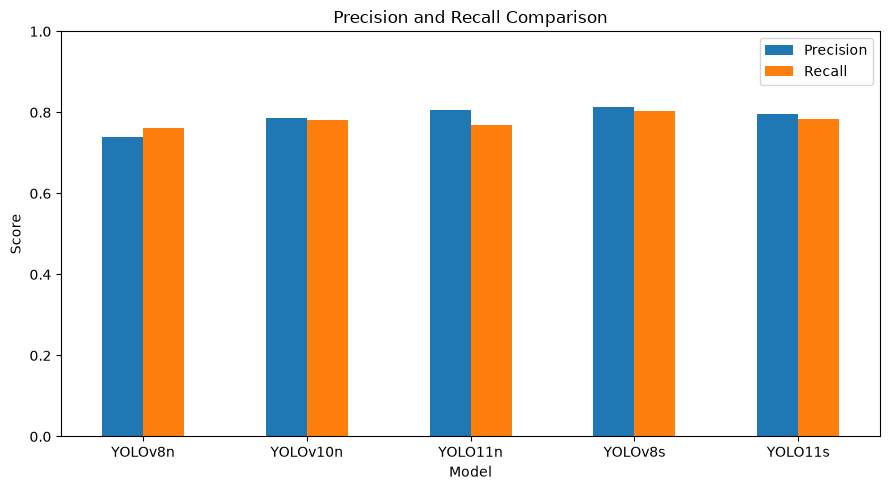

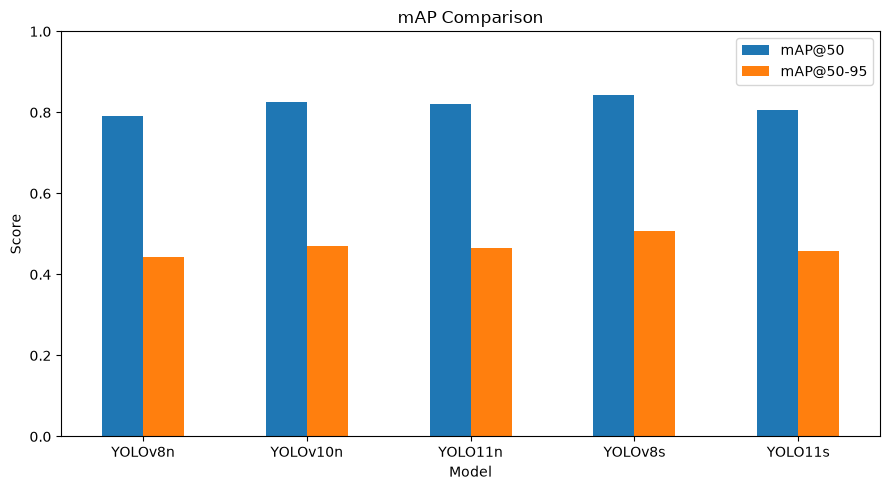

Best overall model: YOLOv8s


In [11]:
comparison.plot(
    x="Model", y=["Precision", "Recall"], kind="bar",
    figsize=(9, 5), ylim=(0, 1), title="Precision and Recall Comparison"
)
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison.plot(
    x="Model", y=["mAP@50", "mAP@50-95"], kind="bar",
    figsize=(9, 5), ylim=(0, 1), title="mAP Comparison"
)
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

metric_columns = ["Precision", "Recall", "F1", "mAP@50", "mAP@50-95"]
comparison["Average"] = comparison[metric_columns].mean(axis=1)
best_model = comparison.loc[comparison["Average"].idxmax(), "Model"]
print("Best overall model:", best_model)


## Test Model


Model: YOLOv8s
Image: image122.jpeg
PPE Status: VIOLATION DETECTED


,Class,Confidence
0,Vest,0.871493
1,Person,0.856809
2,Helmet,0.721790
3,Goggles,0.404777
4,NO-Mask,0.360469


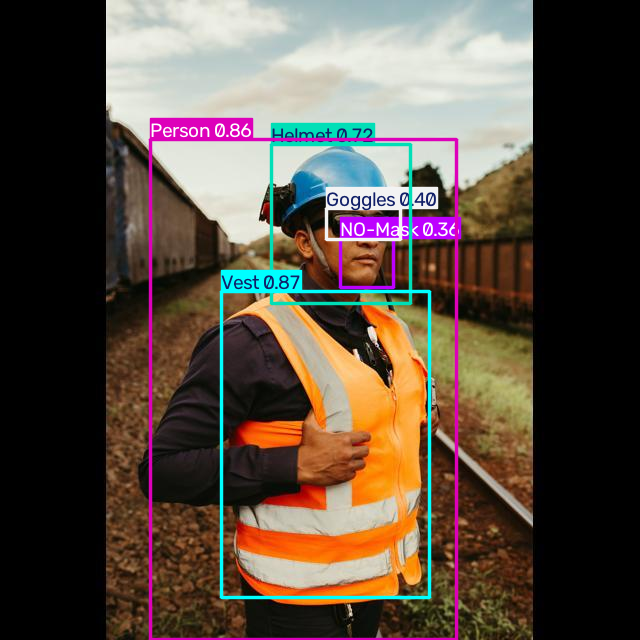

In [37]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
import pandas as pd

selected_model = best_model

test_image_folder = Path(data_config["path"]) / data_config["test"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

if not test_image_folder.is_dir():
    raise FileNotFoundError(f"Test folder not found: {test_image_folder}")

test_images = sorted(
    path
    for path in test_image_folder.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

if not test_images:
    raise ValueError(f"No test images found in: {test_image_folder}")

test_image = test_images[27]

model = YOLO(str(model_paths[selected_model]))
result = model.predict(
    source=str(test_image),
    conf=0.25,
    imgsz=640,
    verbose=False,
)[0]

detections = []

for class_id, score in zip(
    result.boxes.cls.cpu().int().tolist(),
    result.boxes.conf.cpu().tolist(),
):
    detections.append({
        "Class": result.names[class_id],
        "Confidence": float(score),
    })

violation = any(
    item["Class"].lower().replace("_", "-").startswith("no-")
    for item in detections
)

status = (
    "VIOLATION DETECTED"
    if violation
    else "NO EXPLICIT VIOLATION DETECTED"
    if detections
    else "NO DETECTIONS"
)

print("Model:", selected_model)
print("Image:", test_image.name)
print("PPE Status:", status)

display(pd.DataFrame(detections, columns=["Class", "Confidence"]))
display(Image.fromarray(result.plot()[:, :, ::-1]))